# Import

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Đọc file train / test

In [24]:
train_df = pd.read_csv("../../Dataset/data_split/train_data.csv")
test_df = pd.read_csv("../../Dataset/data_split/test_data.csv")

LABEL_NAME = {0: "low", 1: "medium", 2: "high"}
feature_names = [c for c in train_df.columns if c != "quality"]

X_train = train_df[feature_names].to_numpy(dtype=float)
y_train = train_df["quality"].to_numpy(dtype=int)
X_test = test_df[feature_names].to_numpy(dtype=float)
y_test = test_df["quality"].to_numpy(dtype=int)

print("Train:", X_train.shape, "Test:", X_test.shape)
for k in LABEL_NAME:
    print(f"  {k} ({LABEL_NAME[k]}): train = {(y_train == k).sum()}, test = {(y_test == k).sum()}")

Train: (1087, 11) Test: (272, 11)
  0 (low): train = 50, test = 13
  1 (medium): train = 890, test = 222
  2 (high): train = 147, test = 37


# Ý tưởng tổng quát

- Cây quyết định hỏi liên tiếp các câu hỏi dạng *"alcohol ≤ 10.5?"* để chia dữ liệu thành các nhóm ngày càng thuần (gần như chỉ chứa một loại chất lượng). Nhóm cuối cùng (lá) đưa ra dự đoán.
- Random Forest = nhiều cây quyết định, mỗi cây học trên một mẫu ngẫu nhiên của dữ liệu và chỉ được xét vài đặc trưng ngẫu nhiên ở mỗi lần chia. Các cây bỏ phiếu, nhãn nào nhiều phiếu nhất thì thắng.

# Hàm Gini

**Gini** đo mức độ "lẫn lộn" của một nhóm mẫu:
- 0 -> cả nhóm chỉ có một lớp (thuần)
- càng lớn -> các lớp càng trộn lẫn

Cây sẽ chọn cách chia làm cho Gini sau khi chia thấp nhất.
w là trọng số của từng mẫu dùng để lớp hiếm được tính nặng hơn, giúp mô hình không bỏ qua lớp ít xuất hiện.

In [25]:
def gini(y, w):
    counts = np.bincount(y, weights=w, minlength=3)   
    p = counts / counts.sum()                         
    return 1 - np.sum(p ** 2)

# DecisionTree

Mỗi nút của cây là một trong hai loại:
- nút quyết định: có `feature`, `threshold` và hai nhánh `left` / `right` (mẫu có `x[feature] <= threshold` đi sang trái);
- nút lá: chỉ có `label` (nhãn dự đoán).

Cách xây cây (`build`): nếu đủ điều kiện dừng thì tạo lá, nếu không thì tìm cách chia tốt nhất (`best_split`), tách dữ liệu làm hai phần rồi xây tiếp hai nhánh.

In [26]:
class Node:
    def __init__(self, feature=None, threshold=None, left=None, right=None, label=None):
        self.feature, self.threshold = feature, threshold
        self.left, self.right = left, right
        self.label = label                       


class DecisionTree:
    def __init__(self, max_depth=8, min_samples_leaf=3, n_feats=5, n_thresholds=9, rng=None):
        self.max_depth = max_depth               
        self.min_samples_leaf = min_samples_leaf 
        self.n_feats = n_feats                   
        self.n_thresholds = n_thresholds        
        self.rng = rng

    def fit(self, X, y, w):
        self.root = self.build(X, y, w, depth=0)
        return self

    def build(self, X, y, w, depth):
        label = np.bincount(y, weights=w, minlength=3).argmax()
        
        if depth >= self.max_depth or len(np.unique(y)) == 1 or len(y) < 2 * self.min_samples_leaf:
            return Node(label=label)

        feature, threshold = self.best_split(X, y, w)
        if feature is None:                    
            return Node(label=label)

        go_left = X[:, feature] <= threshold
        return Node(feature, threshold,
                    left=self.build(X[go_left], y[go_left], w[go_left], depth + 1),
                    right=self.build(X[~go_left], y[~go_left], w[~go_left], depth + 1))

    def best_split(self, X, y, w):
        best_feature, best_threshold = None, None
        best_gini = gini(y, w)                  

        for feature in self.rng.choice(X.shape[1], self.n_feats, replace=False):
            
            percents = np.linspace(0, 100, self.n_thresholds + 2)[1:-1]
            thresholds = np.unique(np.percentile(X[:, feature], percents))

            for threshold in thresholds:
                go_left = X[:, feature] <= threshold
                if go_left.sum() < self.min_samples_leaf or (~go_left).sum() < self.min_samples_leaf:
                    continue                    

                w_left, w_right = w[go_left].sum(), w[~go_left].sum()
                g = (w_left * gini(y[go_left], w[go_left]) +
                     w_right * gini(y[~go_left], w[~go_left])) / (w_left + w_right)

                if g < best_gini:
                    best_gini, best_feature, best_threshold = g, feature, threshold

        return best_feature, best_threshold

    def predict_one(self, x):
        node = self.root
        while node.label is None:              
            node = node.left if x[node.feature] <= node.threshold else node.right
        return node.label

# RandomForest

Với mỗi cây:
1. Bootstrap: bốc ngẫu nhiên n mẫu có hoàn lại từ tập train (một số mẫu xuất hiện nhiều lần, một số không xuất hiện).
2. Huấn luyện cây trên mẫu đó.

Dự đoán một mẫu: cho mọi cây dự đoán, rồi lấy nhãn có nhiều phiếu nhất.

In [ ]:
class RandomForest:
    def __init__(self, n_trees=50, max_depth=8, min_samples_leaf=3, n_feats=5,
                 n_thresholds=9, balanced=True, seed=42):
        self.n_trees, self.max_depth, self.min_samples_leaf = n_trees, max_depth, min_samples_leaf
        self.n_feats, self.n_thresholds = n_feats, n_thresholds
        self.balanced, self.seed = balanced, seed

    def fit(self, X, y):
        rng = np.random.default_rng(self.seed)   

        w = np.ones(len(y))
        if self.balanced:
            class_weight = len(y) / (3 * np.bincount(y, minlength=3))
            w = class_weight[y]

        self.trees = []
        for _ in range(self.n_trees):
            idx = rng.integers(0, len(y), size=len(y))       
            tree = DecisionTree(self.max_depth, self.min_samples_leaf,
                                self.n_feats, self.n_thresholds, rng)
            tree.fit(X[idx], y[idx], w[idx])
            self.trees.append(tree)
        return self

    def votes(self, x):
        """Số phiếu của từng lớp (0, 1, 2) cho một mẫu x."""
        predictions = [tree.predict_one(x) for tree in self.trees]
        return np.bincount(predictions, minlength=3)

    def predict(self, X):
        return np.array([self.votes(x).argmax() for x in X])

# Huấn luyện

Lớp *medium* chiếm khoảng 82% dữ liệu. Nếu không xử lý, mô hình chỉ cần đoán "medium" cho mọi mẫu cũng đã đúng ~82%, và gần như bỏ qua hai lớp còn lại.
`balanced=True` làm mẫu của lớp hiếm có trọng số lớn hơn để mô hình phải chú ý tới chúng. Đặt `balanced=False` để so sánh.

In [28]:
model = RandomForest(n_trees=50, max_depth=8, min_samples_leaf=3, n_feats=5, balanced=True, seed=42)
model.fit(X_train, y_train)
print("Đã huấn luyện xong", len(model.trees), "cây")

Đã huấn luyện xong 50 cây


# Đánh giá

- **Precision** của một lớp: trong số mẫu mô hình dự đoán là lớp đó, bao nhiêu % đúng.
- **Recall**: trong số mẫu thật sự thuộc lớp đó, mô hình tìm ra được bao nhiêu %.
- **F1**: trung bình điều hòa của Precision và Recall. **Macro-F1** là trung bình F1 của 3 lớp, nên lớp hiếm cũng được tính ngang lớp đông.

In [29]:
def evaluate(y_true, y_pred):
    
    cm = np.zeros((3, 3), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[t][p] += 1

    print(f"Accuracy: {np.mean(y_true == y_pred):.3f}")
    print("Nhãn           Precision  Recall     F1    Support")
    f1_list = []
    for k in range(3):
        tp = cm[k][k]                          
        fp = cm[:, k].sum() - tp                
        fn = cm[k, :].sum() - tp                
        precision = tp / (tp + fp) if tp + fp > 0 else 0
        recall = tp / (tp + fn) if tp + fn > 0 else 0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0
        f1_list.append(f1)
        print(f"{k} ({LABEL_NAME[k]:6s})   {precision:9.3f}  {recall:6.3f}  {f1:6.3f}  {cm[k].sum():7d}")
    print(f"Macro-F1: {np.mean(f1_list):.3f}")
    return cm


y_pred = model.predict(X_test)
cm = evaluate(y_test, y_pred)

baseline = np.bincount(y_test).max() / len(y_test)
print(f"\nBaseline (luôn đoán lớp phổ biến nhất): Accuracy = {baseline:.3f}")

Accuracy: 0.812
Nhãn           Precision  Recall     F1    Support
0 (low   )       0.500   0.231   0.316       13
1 (medium)       0.887   0.883   0.885      222
2 (high  )       0.489   0.595   0.537       37
Macro-F1: 0.579

Baseline (luôn đoán lớp phổ biến nhất): Accuracy = 0.816


## Ma trận nhầm lẫn

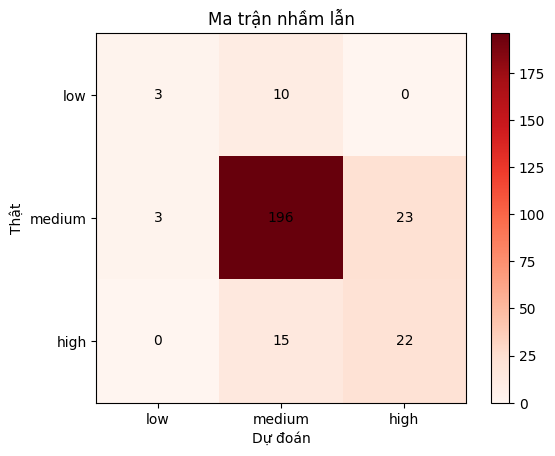

In [30]:
labels = [LABEL_NAME[k] for k in range(3)]
plt.imshow(cm, cmap="Reds")
plt.xticks(range(3), labels)
plt.yticks(range(3), labels)
plt.xlabel("Dự đoán")
plt.ylabel("Thật")
plt.title("Ma trận nhầm lẫn")
plt.colorbar()
for i in range(3):
    for j in range(3):
        plt.text(j, i, cm[i][j], ha="center", va="center")
plt.show()

# Dự đoán một mẫu

In [31]:
x = X_test[0]
votes = model.votes(x)
pred = votes.argmax()

for name, value in zip(feature_names, x):
    print(f"  {name:22s}  {value:.4f}")
print(f"\nDự đoán: {pred} ({LABEL_NAME[pred]})")
print("Phiếu:", {LABEL_NAME[k]: int(votes[k]) for k in range(3)})
print(f"Nhãn thật: {y_test[0]} ({LABEL_NAME[y_test[0]]})")
print(f"Tỷ lệ đồng ý: {votes[pred] / len(model.trees):.1%}")

  fixed acidity           7.7000
  volatile acidity        0.6650
  citric acid             0.0000
  residual sugar          2.4000
  chlorides               0.0900
  free sulfur dioxide     8.0000
  total sulfur dioxide    19.0000
  density                 0.9974
  pH                      3.2700
  sulphates               0.7300
  alcohol                 9.3000

Dự đoán: 1 (medium)
Phiếu: {'low': 1, 'medium': 44, 'high': 5}
Nhãn thật: 1 (medium)
Tỷ lệ đồng ý: 88.0%
